# 교차 검증 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week06/cross_validation/lab/cross_validation.ipynb)

정답 곡선 없이 λ 를 고른다: 돌아가며 숨기고 평균.

- **파트 1**: k 겹 교차 검증 직접 구현 → 손 계산 12.75, λ* = 12.6
- **파트 2**: 한 번 나누기 vs 5겹: 고른 λ 의 흔들림
- **파트 3**: 붓꽃 (안 섞으면?) · 당뇨병 `LassoCV`

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

## 파트 1. k 겹 교차 검증

조각 $j$ = 인덱스 $j, j+k, j+2k, \dots$ (`np.arange(j, m, k)`).

먼저 손 계산: $y = 1, \dots, 10$, 학습 데이터의 평균으로 예측하는 모델, **순서대로** 2개씩 5조각 → 25.25, 6.5, 0.25, 6.5, 25.25 → 12.75.

In [ ]:
y10 = np.arange(1, 11, dtype=float)
fold_mse = []
for j in range(5):
    val = np.arange(2 * j, 2 * j + 2)                     # contiguous pieces of 2
    train = np.setdiff1d(np.arange(10), val)
    pred = None  # TODO: the mean model predicts the training mean
    fold_mse.append(np.mean((y10[val] - pred) ** 2))
print(np.round(fold_mse, 2), "CV =", np.mean(fold_mse))

**예상 결과**

```
[25.25  6.5   0.25  6.5  25.25] CV = 12.75
```

In [ ]:
# Example from the slides: 60 students, 30 features, only 3 matter
rng = np.random.default_rng(4)
X = rng.normal(0, 1, (60, 30))
y = 3 * X[:, 0] - 2 * X[:, 1] + 1.5 * X[:, 2] + rng.normal(0, 3, 60)

def fit_ridge(X, y, lam):                                 # no penalty on the intercept (center first)
    x0, y0 = X.mean(axis=0), y.mean()
    Xc, yc = X - x0, y - y0
    w = np.linalg.solve(Xc.T @ Xc + lam * np.eye(X.shape[1]), Xc.T @ yc)
    return w, y0 - w @ x0

def mse(model, X, y):
    w, b = model
    return np.mean((X @ w + b - y) ** 2)

def cv_errors(X, y, lam, k=5):
    m = len(y); errors = []
    for j in range(k):
        val = np.arange(j, m, k)
        train = None  # TODO: every index not in val
        errors.append(None)  # TODO: MSE on the hidden piece
    return errors

lams = np.logspace(-2, 3, 51)
E = np.array([cv_errors(X, y, lam) for lam in lams])
cv_mean = E.mean(axis=1)
best = int(np.argmin(cv_mean))
print(f"lambda* = {lams[best]:.1f}   CV MSE = {cv_mean[best]:.2f}   fold MSEs = {E[best].round(1)}")
plt.semilogx(lams, E, ":", color="gray", lw=0.8); plt.semilogx(lams, cv_mean, "o-", ms=3)
plt.axvline(lams[best], color="r"); plt.ylim(5, 40); plt.xlabel("lambda"); plt.ylabel("MSE"); plt.show()

**예상 결과**

```
lambda* = 12.6   CV MSE = 15.69   fold MSEs = [19.1  8.3 12.4 24.3 14.3]
```

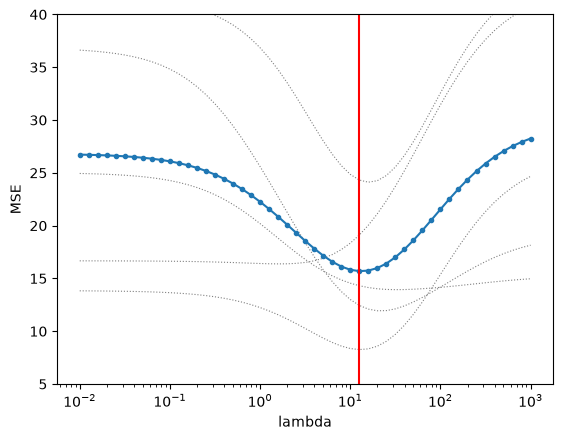

In [ ]:
# Grade it: true error on 20,000 fresh students (possible only because this is a made-up example)
Xt = rng.normal(0, 1, (20000, 30))
yt = 3 * Xt[:, 0] - 2 * Xt[:, 1] + 1.5 * Xt[:, 2] + rng.normal(0, 3, 20000)
true_err = np.array([mse(fit_ridge(X, y, lam), Xt, yt) for lam in lams])
print(f"true best lambda = {lams[np.argmin(true_err)]:.1f}   true error at lambda* = {true_err[best]:.2f}")
print(f"true error at 0.01 = {true_err[0]:.2f},  at 1000 = {true_err[-1]:.2f}")

**예상 결과**

```
true best lambda = 12.6   true error at lambda* = 11.56
true error at 0.01 = 12.78,  at 1000 = 22.50
```

## 파트 2. 한 번만 나누면?

60명을 학습 48 · 검증 12 로 무작위로 한 번 나눠 λ 를 고른다. 10번 반복.

In [ ]:
chosen = []
for s in range(10):
    p = np.random.default_rng(100 + s).permutation(60)
    tr, va = p[:48], p[48:]
    val_err = [mse(fit_ridge(X[tr], y[tr], lam), X[va], y[va]) for lam in lams]
    chosen.append(None)  # TODO: lambda with the smallest validation error
print("single split choices:", np.round(chosen, 2))
print(f"range: {min(chosen):.2f} ~ {max(chosen):.2f}   (5-fold chose {lams[best]:.1f})")

**예상 결과**

```
single split choices: [ 63.1   39.81   7.94  19.95  25.12   7.94 158.49  15.85  19.95   2.51]
range: 2.51 ~ 158.49   (5-fold chose 12.6)
```

## 파트 3. 실제 데이터

### 붓꽃: 정렬된 데이터를 섞지 않으면
붓꽃 150송이는 종 순서대로 저장돼 있다. 처음 실행하면 CSV 를 내려받는다.

In [ ]:
import pandas as pd
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression, LassoCV

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/iris.csv"):
    import urllib.request; urllib.request.urlretrieve(url, "data/iris.csv")
df = pd.read_csv("data/iris.csv")
print(df["species"].iloc[[0, 49, 50, 99, 100, 149]].tolist())
Xi, yi = df.iloc[:, :4].to_numpy(), df["species"].to_numpy()
clf = LogisticRegression(max_iter=1000)
print("KFold(3), no shuffle :", cross_val_score(clf, Xi, yi, cv=KFold(3)).round(2))
strat = None  # TODO: shuffled, class-balanced 3 folds
print("Stratified, shuffled :", cross_val_score(clf, Xi, yi, cv=strat).round(2))

**예상 결과**

```
['setosa', 'setosa', 'versicolor', 'versicolor', 'virginica', 'virginica']
KFold(3), no shuffle : [0. 0. 0.]
Stratified, shuffled : [0.96 0.98 0.94]
```

### 당뇨병: LassoCV 로 λ 고르기
`LassoCV` 는 λ(`alpha`) 후보마다 k 겹 교차 검증을 해서 가장 좋은 λ 를 고르고, 데이터 전부로 다시 학습까지 한다.

In [ ]:
from sklearn.datasets import load_diabetes
Xd, yd = load_diabetes(return_X_y=True)
model = LassoCV(alphas=np.logspace(-3, 1, 30), cv=KFold(5, shuffle=True, random_state=0)).fit(Xd, yd)
print(f"chosen alpha = {model.alpha_:.4f}   features used = {int((np.abs(model.coef_) > 1e-9).sum())} / 10")
cv_mse = model.mse_path_.mean(axis=1)
plt.semilogx(model.alphas_, np.sqrt(cv_mse), "o-"); plt.axvline(model.alpha_, color="r")
plt.xlabel("alpha (lambda)"); plt.ylabel("CV RMSE"); plt.show()

**예상 결과**

```
chosen alpha = 0.0329   features used = 8 / 10
```

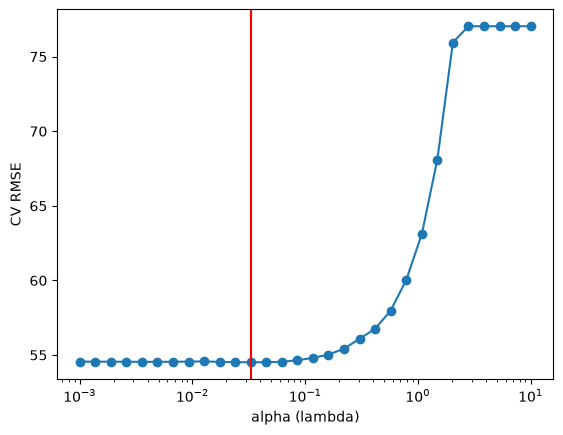

**확인 질문**
1. 파트 1 에서 k 를 2, 10, 60 (leave-one-out) 으로 바꾸면 λ* 는 어떻게 되나?
2. 파트 2 의 결과로, 검증 데이터를 한 번만 떼는 방식의 문제를 한 문장으로 설명해 보자.
3. 파트 3 의 붓꽃에서 `KFold(3, shuffle=True, random_state=0)` (층화 없이 섞기만) 은 어떤가?
4. 파트 3 의 `LassoCV` 가 고른 모델의 최종 성능을 정직하게 보고하려면 무엇이 더 필요한가?

데이터 출처: Fisher (1936) Iris, seaborn-data 사본 · Efron et al. (2004) Diabetes, scikit-learn.